# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 4</span>

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

# Exercise 04.2

## Result 

We are then asked to start the simulation from a very low entropic initial configuration, let the system evolve and show that it has converged to Maxwell-Boltmann distribution.

The interatomic interactions across all phases are modelled via the Lennard-Jones potential, modified with a spatial cut-off $r_c$:

$$V_{\text{LJ}}(r) = 4\epsilon \left[ \left(\frac{\sigma}{r}\right)^{12} - \left(\frac{\sigma}{r}\right)^6 \right]$$

The following figures show the behaviour of the system in the **gas phase** (reduced density $\rho^* = 0.05$, $N = 108$ particles, cut-off radius $r_c = 5.0$). The simulation uses a time step $\delta t = 0.001$ and consists of 1000 blocks of 50 steps each.

The system is prepared in a very low-entropy state: the particles occupy an fcc lattice filling only half of the simulation box in each dimension, and every particle has a single non-zero velocity component, $\pm v_{T^*}$, with $v_{T^*} = \sqrt{3T^*}$. The initial speed distribution is therefore a Dirac delta centred at $v_{T^*}$. The input temperature is set to $T^* = 2.7$. Since the total energy is conserved, the kinetic energy is partly converted into potential energy as the gas expands and the particles start to interact, so the temperature decreases during the relaxation and settles at an effective value $T^*_{\rm eff} \simeq 2.0$. In the gas phase the kinetic energy dominates, while the potential energy per particle approaches zero.

The energy plot shows that $K$ and $U$ relax towards constant average values in the first blocks, while the total energy $E = K + U$ stays constant, which confirms the quality of the Verlet integration. The temperature plot shows the same relaxation: it starts near the input value and converges to $T^*_{\rm eff}$.

The last figure shows the histogram of the speeds, averaged over each block, at different stages of the evolution:

* **Block 1:** the distribution is still a narrow peak around $v_{T^*} = \sqrt{3T^*} \simeq 2.85$, close to the initial delta function.
* **Intermediate blocks:** collisions redistribute the kinetic energy among the particles and the peak broadens, with the appearance of both slow and fast particles.
* **Equilibrium:** the histogram, averaged over the last part of the simulation, agrees with the Maxwell–Boltzmann distribution $p(v^*, T^*_{\rm eff})$ computed with the effective temperature $T^*_{\rm eff}$ (red dashed line).

Since $N = 108$ is small, the histograms of single blocks are affected by statistical noise, which is why the equilibrium panel is obtained by averaging over many blocks.
Indeed, to overcome this issue and obtain a smooth curve, the final panel averages over a large number of final blocks (n_last = 500). This smooths out the statistical noise and allows for an accurate verification of the agreement between the simulation and theoretical statistical mechanics.

### Discussion on Time Reversal and Entropy

The evolution of the system toward states of greater disorder reflects the increase in entropy and the system's tendency to explore more homogeneous spatial configurations. Regarding the system's behavior when reversing the direction of time:

1. **In theory (equations of motion):** The laws of classical mechanics (and consequently the Verlet integration algorithm) are time-reversal symmetric. If at a given instant we were to instantaneously reverse all particle velocities ($\vec{v}_i \to -\vec{v}_i$), the system should theoretically retrace its trajectory backward, returning to the initial ordered state (FCC crystal lattice at low entropy).
2. **In practice (numerical simulation and thermodynamics):** In the reality of a computer numerical simulation, this ideal behavior is not observable in the long term. Due to floating-point representation rounding errors and the strongly chaotic nature of the many-body system, a velocity inversion would allow the system to retrace previous steps for only a very limited time interval. Afterwards, numerical errors dominate, causing the trajectory to diverge.

Finally, the animation in the last cell of the notebook allows a qualitative inspection of the dynamics: the particles, initially packed in the crystal occupying half of the box, expand and spread over the whole simulation volume, moving as a gas.

---

**Exercise**

By means of your upgraded code, <span style="color:red">perform MD simulations via a Lennard-Jones model</span> ( e.g. Argon parameters: $\sigma = 0.34$ nm, $\epsilon/k_B = 120$ K, $m=39.948$ amu) in the following conditions:
- gas phase: $\rho^\star = 0.05$, $T^\star \sim  2.0$ (cut-off radius: $r_c = 5.0$)

starting from a <span style="color:red">**very low entropic** initial configuration</span>:
1. initial **particle positions**: <span style="color:red">fcc crystal occupying half of the simulation box in each dimension</span>
2. initial **velocity distribution**: <span style="color:red">$p_\delta(v^*,T^*) = \delta\left( v^* - v_{T^*}\right)$</span> where $v_{T^*}$ is suitably connected to $T^*$. For example, this condition could be obtained by imposing that every particle has an initial velocity $\pm v_{T^*}$ for **only one** of its velocity components: $v_x$, $v_y$, $v_z$.

The goal is to show that, by evolving such initial condition via a Molecular Dynamics simulation, the velocity distribution tends to approximate the Maxwell–Boltzmann distribution.

- **Produce some pictures that show this convergence**
- The evolution of the system moves towards the increasing of entropy (more homeogeneous configuration of particles)? What would you find by changing the direction of time? Comment on these aspects in your jupyter-notebook

**Note that** the MD simulation will conserve the total energy; thus the kinetic energy and the temperature are not constant of motion ... the comparison should be done with $p(v^*,T^*_{\rm eff})$ where $T^*_{\rm eff}$ is the effective temperature obtained once the system has been equilibrated. 



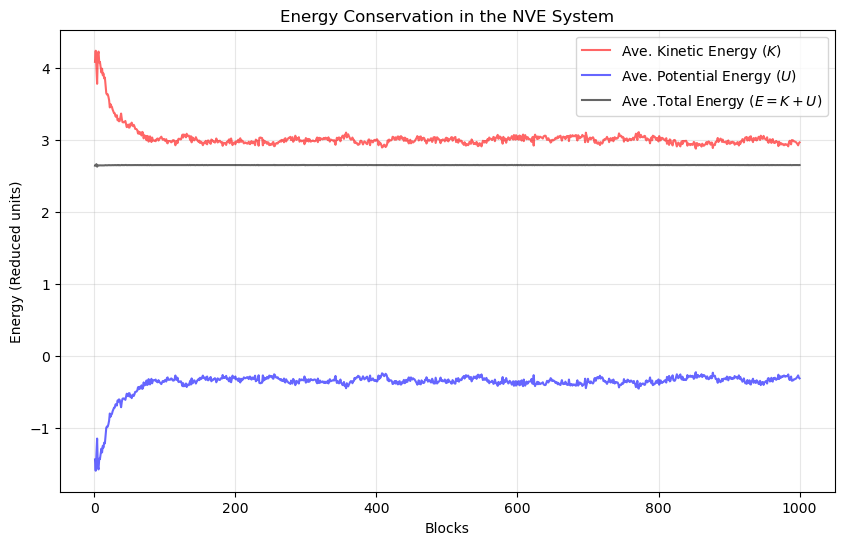

In [53]:


# Carico i dati
data1 = np.loadtxt("kinetic_energy.dat")
data2 = np.loadtxt("potential_energy.dat")
data3 = np.loadtxt("total_energy.dat")

# Definisco le x (blocchi) e le y (energie)
blocks = data1[:, 0]
ke = data1[:, 1]
pe = data2[:, 1]
te=data3[:,1]

plt.figure(figsize=(10,6))

# Plot delle componenti
plt.plot(blocks, ke, label='Ave. Kinetic Energy ($K$)', color='red', alpha=0.6)
plt.plot(blocks, pe, label='Ave. Potential Energy ($U$)', color='blue', alpha=0.6)
plt.plot(blocks, te, label='Ave .Total Energy ($E=K+U$)', color='black', alpha=0.6)

# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Energy Conservation in the NVE System")
plt.xlabel("Blocks")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

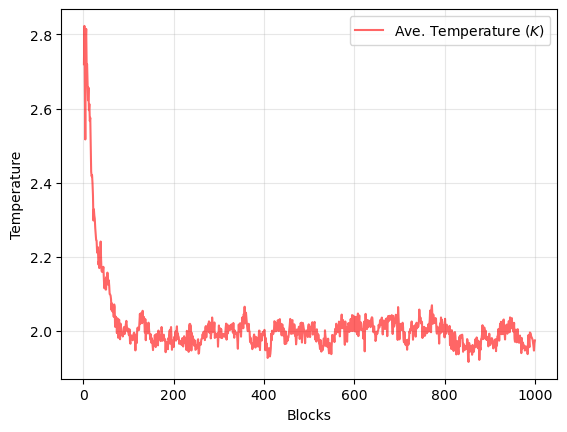

In [55]:
# Carico i dati
data4 = np.loadtxt("temperature.dat")
te = data4[:,1]
blocks_te = data4[:, 0]

# Plot delle componenti
plt.plot(blocks_te, te, label='Ave. Temperature ($K$)', color='red', alpha=0.6)

plt.title("")
plt.xlabel("Blocks")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


v_max = 6.573  ->  TEMP = 2.700
T_eff = 1.995


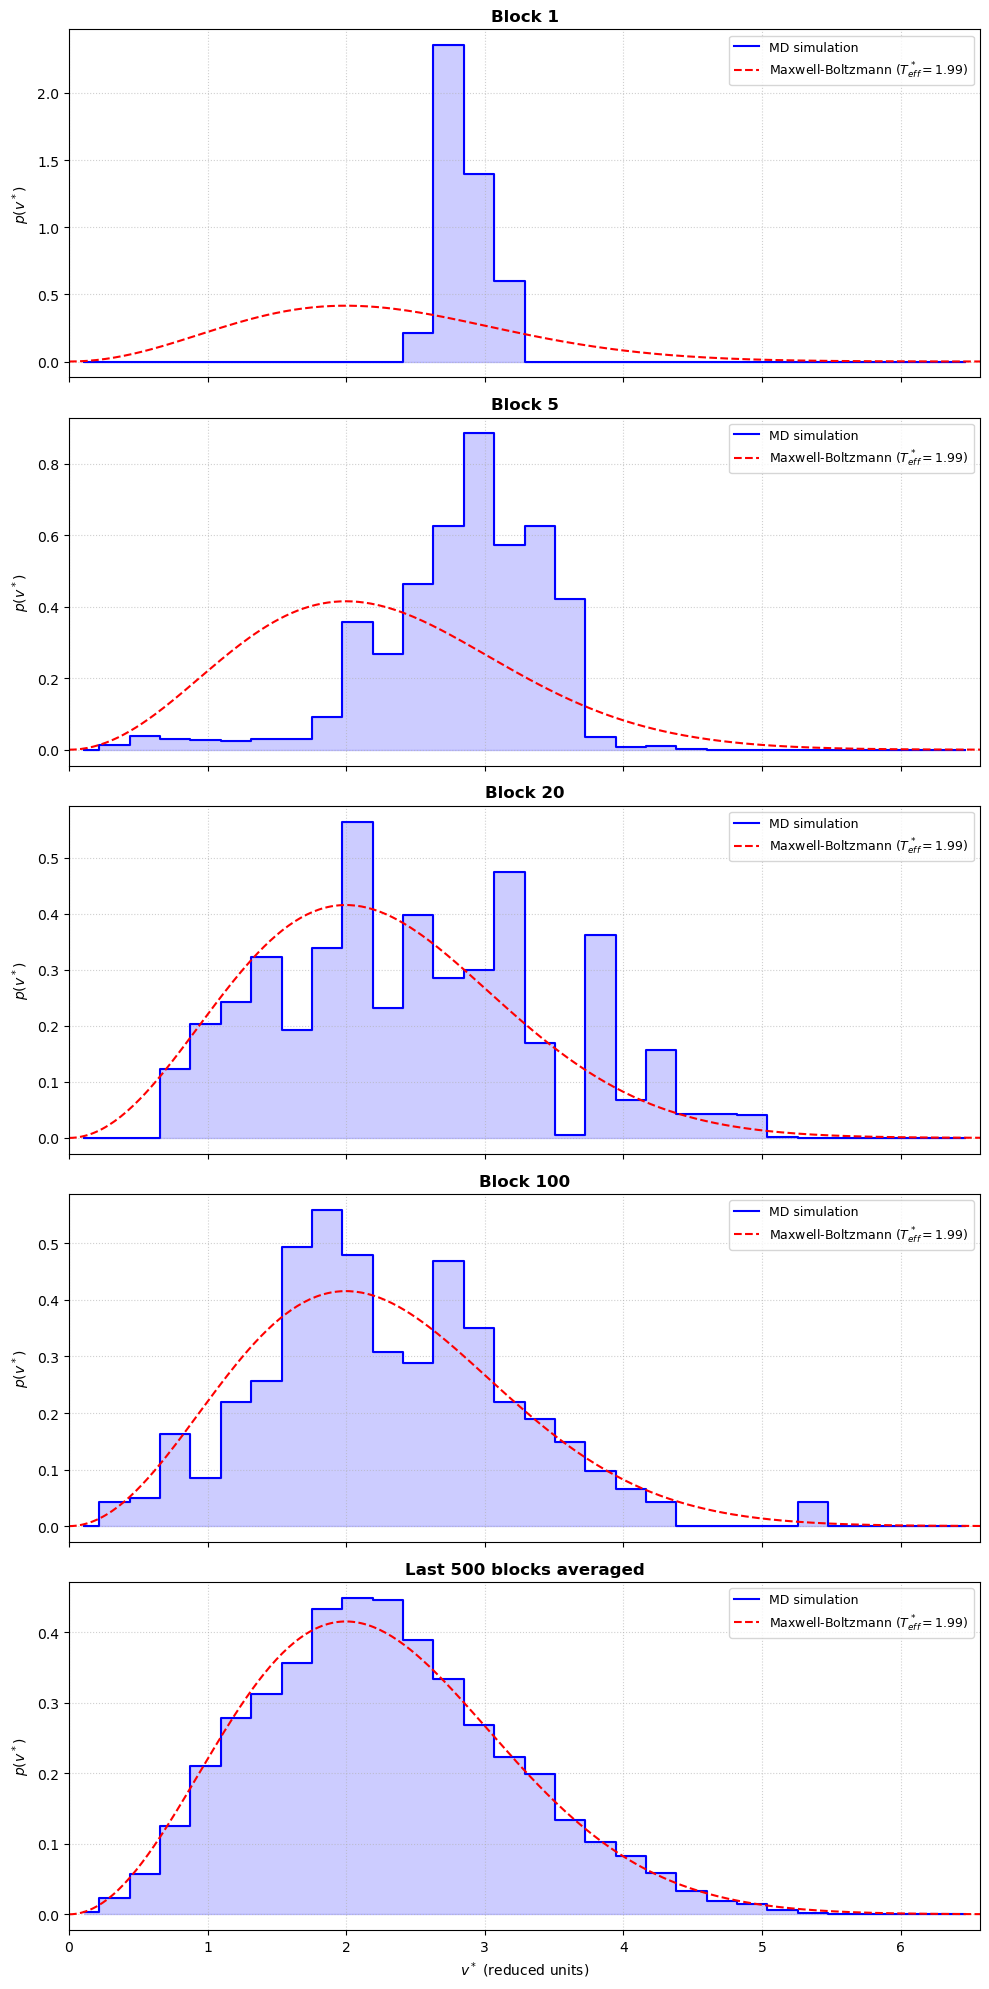

In [63]:
data = np.loadtxt("pofv_evolution.dat")
n_bins = 30
n_blocks = int(data[:, 0].max())
H = data[:, 1].reshape(n_blocks, n_bins)      # block-averaged p(v), one row per block

# rebuild the v axis: sum(p) = 1/dv because p is normalised
dv = 1.0 / H[0].sum()
v = (np.arange(n_bins) + 0.5) * dv
v_max = n_bins * dv
print(f"v_max = {v_max:.3f}  ->  TEMP = {(v_max/4)**2:.3f}")

# effective temperature from the last blocks
n_last = 500
try:
    T_eff = np.loadtxt("temperature.dat")[-n_last:, 1].mean()
except OSError:
    T_eff = np.sum(H[-n_last:].mean(axis=0) * v**2) * dv / 3
print(f"T_eff = {T_eff:.3f}")

vv = np.linspace(0, v_max, 300)
mb = np.sqrt(2/np.pi) * vv**2 / T_eff**1.5 * np.exp(-vv**2 / (2*T_eff))

panels = [(f"Block {k}", H[k-1]) for k in (1, 5, 20, 100)]
panels.append((f"Last {n_last} blocks averaged", H[-n_last:].mean(axis=0)))

fig, axes = plt.subplots(len(panels), 1, figsize=(10, 4*len(panels)), sharex=True)
for ax, (title, h) in zip(axes, panels):
    ax.step(v, h, where='mid', color='blue', label='MD simulation')
    ax.fill_between(v, h, step='mid', alpha=0.2, color='blue')
    ax.plot(vv, mb, 'r--', lw=1.5, label=rf'Maxwell-Boltzmann ($T^*_{{eff}}={T_eff:.2f}$)')
    ax.set_xlim(0, v_max)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(r"$p(v^*)$")
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, ls=':', alpha=0.6)
axes[-1].set_xlabel(r"$v^*$ (reduced units)")
plt.tight_layout()
plt.show()

In [2]:
from IPython.display import Video
Video("simulazione.mp4", width=600, embed=True)